# Entrega 2 — CNN do zero e comparação com YOLO

## 1. Introdução

Este arquivo tem como objetivo desenvolver uma Rede Neural Convolucional (CNN) do zero para classificar imagens em duas categorias: controle e copo.

A implementação utiliza TensorFlow e Keras para preparar os dados, construir a arquitetura da rede, realizar o treinamento e avaliar os resultados. Também são analisados o tempo de treinamento e o tempo de inferência, permitindo utilizar essas informações posteriormente na comparação com os modelos YOLO.

O experimento foi executado no Google Colab, com os dados armazenados no Google Drive.

In [ ]:

import os
from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

base = "/content/drive/MyDrive/Fase 6"

print("A pasta Fase 6 existe?", os.path.isdir(base))

if os.path.isdir(base):
    print("\nConteúdo da pasta Fase 6:")
    print(os.listdir(base))

    print("\nPastas de dataset encontradas:")
    for raiz, pastas, arquivos in os.walk(base):
        pastas[:] = [
            p for p in pastas
            if p not in ["results", ".ipynb_checkpoints"]
        ]

        if "Dataset" in pastas or "images" in pastas or "labels" in pastas:
            print(raiz, "->", pastas)
else:
    print("O caminho base não foi encontrado.")

Mounted at /content/drive
A pasta Fase 6 existe? True

Conteúdo da pasta Fase 6:
['Dataset', 'results', 'data.yaml', 'CNN']

Pastas de dataset encontradas:
/content/drive/MyDrive/Fase 6 -> ['Dataset', 'CNN']
/content/drive/MyDrive/Fase 6/Dataset -> ['images', 'labels']


## 2. Verificação e organização dos dados

Inicialmente, é verificada a estrutura de diretórios utilizada no experimento, incluindo a existência da pasta principal, das imagens e dos rótulos do dataset.

O conjunto original está organizado em três partições: treinamento (`train`), validação (`val`) e teste (`test`). Essa partição permite treinar o modelo, acompanhar seu desempenho durante o treinamento e avaliar sua capacidade de classificação em imagens reservadas para teste.

In [ ]:

import os

base_dataset = "/content/drive/MyDrive/Fase 6/Dataset"

for tipo in ["images", "labels"]:
    print(f"\n{'=' * 15} {tipo.upper()} {'=' * 15}")

    caminho_tipo = os.path.join(base_dataset, tipo)

    for conjunto in ["train", "val", "test"]:
        caminho = os.path.join(caminho_tipo, conjunto)

        if os.path.isdir(caminho):
            arquivos = os.listdir(caminho)
            print(f"{conjunto}: {len(arquivos)} arquivos")
            print("Exemplos:", arquivos[:5])
        else:
            print(f"{conjunto}: PASTA NÃO ENCONTRADA")


=============== IMAGES ===============
train: 64 arquivos
Exemplos: ['controle2.jpg', 'controle3.jpg', 'controle1.jpg', 'controle4.jpg', 'controle28.jpg']
val: 8 arquivos
Exemplos: ['controle20.jpg', 'controle30.jpg', 'copo20.jpg', 'copo40.jpg', 'copo10.jpg']
test: 8 arquivos
Exemplos: ['controle29.jpg', 'copo29.jpg', 'controle19.jpg', 'copo19.jpg', 'controle9.jpg']

=============== LABELS ===============
train: 64 arquivos
Exemplos: ['controle23.txt', 'controle17.txt', 'copo35.txt', 'controle1.txt', 'copo25.txt']
val: 8 arquivos
Exemplos: ['copo40.txt', 'copo20.txt', 'controle40.txt', 'controle10.txt', 'controle20.txt']
test: 8 arquivos
Exemplos: ['copo29.txt', 'controle29.txt', 'controle9.txt', 'controle19.txt', 'copo9.txt']


## 3. Preparação do dataset para classificação

Como a CNN será utilizada para classificação de imagens, os arquivos são reorganizados em diretórios separados por classe. A estrutura segue o formato esperado pela função `image_dataset_from_directory`, do TensorFlow.

As imagens são distribuídas entre as pastas `train`, `val` e `test`, e dentro de cada uma delas são separadas nas categorias `controle` e `copo`. A classificação é realizada com base nos prefixos dos nomes dos arquivos.

Essa etapa prepara os dados para que os rótulos sejam associados automaticamente às imagens durante o carregamento.

In [ ]:

import os
import shutil

base = "/content/drive/MyDrive/Fase 6"
dataset = os.path.join(base, "Dataset")
cnn = os.path.join(base, "CNN")

classes = ["controle", "copo"]
conjuntos = ["train", "val", "test"]
extensoes = (".jpg", ".jpeg", ".png", ".webp")

for conjunto in conjuntos:
    for classe in classes:
        os.makedirs(
            os.path.join(cnn, conjunto, classe),
            exist_ok=True
        )

for conjunto in conjuntos:
    origem = os.path.join(dataset, "images", conjunto)

    for arquivo in os.listdir(origem):
        if not arquivo.lower().endswith(extensoes):
            continue

        nome = arquivo.lower()

        if nome.startswith("controle"):
            classe = "controle"
        elif nome.startswith("copo"):
            classe = "copo"
        else:
            print(f"Arquivo ignorado: {arquivo}")
            continue

        destino = os.path.join(cnn, conjunto, classe, arquivo)
        shutil.copy2(os.path.join(origem, arquivo), destino)

print("RESUMO DA CNN")

for conjunto in conjuntos:
    total = 0
    print(f"\n{conjunto.upper()}")

    for classe in classes:
        pasta = os.path.join(cnn, conjunto, classe)
        quantidade = sum(
            1 for f in os.listdir(pasta)
            if f.lower().endswith(extensoes)
        )
        total += quantidade
        print(f"{classe}: {quantidade} imagens")

    print(f"Total: {total} imagens")

RESUMO DA CNN

TRAIN
controle: 32 imagens
copo: 32 imagens
Total: 64 imagens

VAL
controle: 4 imagens
copo: 4 imagens
Total: 8 imagens

TEST
controle: 4 imagens
copo: 4 imagens
Total: 8 imagens


## 4. Carregamento e configuração dos dados

Os conjuntos de treinamento, validação e teste são carregados utilizando o TensorFlow. As imagens são redimensionadas para 128 × 128 pixels e agrupadas em lotes de oito imagens.

A semente aleatória é definida como 42 para favorecer a reprodutibilidade das operações aleatórias utilizadas no experimento. O conjunto de treinamento utiliza embaralhamento, enquanto os conjuntos de validação e teste mantêm a ordem dos arquivos.

As classes são identificadas automaticamente a partir dos nomes das pastas, permitindo associar as saídas da rede às categorias correspondentes.

In [ ]:
import tensorflow as tf
import time
import numpy as np

SEMENTE = 42
tf.keras.utils.set_random_seed(SEMENTE)

IMG_SIZE = (128, 128)
BATCH_SIZE = 8

caminho_cnn = "/content/drive/MyDrive/Fase 6/CNN"

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{caminho_cnn}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEMENTE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{caminho_cnn}/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{caminho_cnn}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("\nClasses:", train_ds.class_names)
print("Treino:", train_ds.cardinality().numpy(), "lotes")
print("Validação:", val_ds.cardinality().numpy(), "lotes")
print("Teste:", test_ds.cardinality().numpy(), "lotes")

Found 64 files belonging to 2 classes.
Found 8 files belonging to 2 classes.
Found 8 files belonging to 2 classes.

Classes: ['controle', 'copo']
Treino: 8 lotes
Validação: 1 lotes
Teste: 1 lotes


## 5. Construção da arquitetura da CNN

A rede neural convolucional é construída do zero, sem utilização de pesos pré-treinados. A arquitetura recebe imagens RGB de dimensões 128 × 128 e normaliza os valores dos pixels para o intervalo entre 0 e 1.

A rede possui três camadas convolucionais, com 16, 32 e 64 filtros, respectivamente, intercaladas com operações de Max Pooling. Em seguida, a camada Global Average Pooling resume as características extraídas, e uma camada densa realiza o processamento final antes da classificação.

A camada de saída possui dois neurônios com ativação Softmax, correspondentes às classes `controle` e `copo`. A função de perda utilizada é `sparse_categorical_crossentropy`, o otimizador é Adam e a métrica acompanhada durante o treinamento é a acurácia.

In [ ]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(2, activation="softmax")
])


model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,730 (100.51 KB)

 Trainable params: 25,730 (100.51 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Treinamento do modelo

O treinamento utiliza até 30 épocas e o mecanismo Early Stopping, configurado para monitorar a perda do conjunto de validação. Caso não haja melhora durante cinco épocas consecutivas, o treinamento é interrompido.

A opção `restore_best_weights=True` permite recuperar os pesos correspondentes à melhor perda de validação observada. O tempo total de treinamento e a quantidade de épocas executadas são registrados para análise posterior.

Essa configuração busca evitar treinamentos desnecessariamente longos e reduzir o risco de perda de capacidade de generalização.

In [ ]:

import time
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

inicio_treino = time.perf_counter()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping],
    verbose=1
)

fim_treino = time.perf_counter()
tempo_treino = fim_treino - inicio_treino

print(f"\nTempo de treinamento: {tempo_treino:.2f} segundos")
print(f"Épocas executadas: {len(history.history['loss'])}")

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 159ms/step - accuracy: 0.5625 - loss: 0.6936 - val_accuracy: 0.5000 - val_loss: 0.6799
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.5312 - loss: 0.6855 - val_accuracy: 0.8750 - val_loss: 0.6715
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.7969 - loss: 0.6452 - val_accuracy: 0.7500 - val_loss: 0.6388
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.6875 - loss: 0.6225 - val_accuracy: 0.7500 - val_loss: 0.5880
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.8438 - loss: 0.5515 - val_accuracy: 0.8750 - val_loss: 0.5419
Epoch 6/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.8125 - loss: 0.4991 - val_accuracy: 0.7500 - val_loss: 0.4909
Epoch 7/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.8281 - loss: 0.4788 - val_accuracy: 0.6250 - val_loss: 0.4438
Epoch 8/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step - accuracy: 0.8125 - loss: 0.4039 - val_accuracy: 0.7500 - val_loss:

### Observação sobre o treinamento

O treinamento da CNN já é realizado na seção anterior, com até 30 épocas e `EarlyStopping`. Esta célula duplicava o treinamento por mais 10 épocas e causava inconsistência entre o histórico, as métricas e os gráficos. Ela foi substituída por esta observação para manter um único treinamento por execução do notebook.

In [ ]:

test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Acurácia da CNN no conjunto de teste: {test_accuracy * 100:.2f}%")

## 7. Avaliação da CNN

Após o treinamento, o modelo é avaliado utilizando o conjunto de teste, que não participa da atualização dos pesos durante o treinamento.

São calculadas a acurácia e a perda, além das métricas de precisão, recall e F1-score para cada classe. A matriz de confusão permite visualizar a quantidade de classificações corretas e os possíveis erros entre `controle` e `copo`.

Essas métricas oferecem diferentes perspectivas sobre o desempenho do classificador. Entretanto, os resultados devem ser interpretados considerando o tamanho reduzido do conjunto de teste.

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

resultados = model.evaluate(test_ds, return_dict=True, verbose=0)

print("Resultados no conjunto de teste:")
for metrica, valor in resultados.items():
    print(f"{metrica}: {valor:.4f}")

y_real = np.concatenate([
    y.numpy() for _, y in test_ds
])

probabilidades = model.predict(test_ds, verbose=0)
y_previsto = np.argmax(probabilidades, axis=1)

print("\nRelatório de classificação:")
print(classification_report(
    y_real,
    y_previsto,
    labels=[0, 1],
    target_names=train_ds.class_names,
    zero_division=0
))

print("Matriz de confusão:")
print(confusion_matrix(y_real, y_previsto, labels=[0, 1]))

Resultados no conjunto de teste:
accuracy: 1.0000
loss: 0.1155

Relatório de classificação:
              precision    recall  f1-score   support

    controle       1.00      1.00      1.00         4
        copo       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8

Matriz de confusão:
[[4 0]
 [0 4]]


### Resultados e análise da CNN

A rede neural foi construída do zero, utilizando três camadas convolucionais e camadas densas para classificar imagens nas categorias `controle` e `copo`. O modelo possui 25.730 parâmetros treináveis.

O treinamento foi concluído em 25 épocas, com duração de 44.02 segundos. No conjunto de teste, composto por oito imagens, a CNN obteve acurácia de 100%, perda de 0.1155 e F1-score de 1.00 para ambas as classes. A matriz de confusão não apresentou classificações incorretas.

Apesar dos resultados positivos, o conjunto de teste é pequeno, contendo apenas quatro imagens por classe. Portanto, o desempenho observado não permite garantir a mesma precisão em imagens diferentes das utilizadas no experimento. São necessários testes adicionais para avaliar a capacidade de generalização do modelo.


## 8. Salvamento do modelo

Após o treinamento e a avaliação, o modelo é salvo no formato `.keras` no Google Drive. Esse procedimento permite preservar a arquitetura e os pesos aprendidos, possibilitando carregar o modelo posteriormente sem executar um novo treinamento.

In [ ]:
import os

caminho_modelo = "/content/drive/MyDrive/Fase 6/CNN/cnn_controle_copo.keras"

model.save(caminho_modelo)

print("Modelo salvo:", os.path.exists(caminho_modelo))
print("Caminho:", caminho_modelo)

Modelo salvo: True
Caminho: /content/drive/MyDrive/Fase 6/CNN/cnn_controle_copo.keras


## 9. Medição do tempo de inferência

O tempo de inferência é medido executando a rede repetidamente sobre uma imagem já carregada na memória. Antes das medições, são realizadas dez execuções de aquecimento, seguidas de cem execuções cronometradas.

São calculados o tempo médio e o tempo mediano por imagem. Como a medição utiliza uma imagem previamente carregada, ela representa o tempo de execução da rede, sem incluir a leitura do arquivo ou o pré-processamento externo. O resultado também depende do hardware e das condições de execução do ambiente.

In [ ]:

import time
import numpy as np
import tensorflow as tf


imagem_teste, rotulo_real = next(iter(test_ds.unbatch().batch(1)))


for _ in range(10):
    _ = model(imagem_teste, training=False)


repeticoes = 100
tempos = []

for _ in range(repeticoes):
    inicio = time.perf_counter()
    _ = model(imagem_teste, training=False)
    fim = time.perf_counter()
    tempos.append(fim - inicio)

tempo_medio_ms = np.mean(tempos) * 1000
tempo_mediano_ms = np.median(tempos) * 1000

print(f"Tempo médio por imagem: {tempo_medio_ms:.3f} ms")
print(f"Tempo mediano por imagem: {tempo_mediano_ms:.3f} ms")
print(f"Dispositivo disponível: {tf.config.list_physical_devices()}")

Tempo médio por imagem: 18.965 ms
Tempo mediano por imagem: 18.507 ms
Dispositivo disponível: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### Tempo de treinamento dos modelos YOLO

Nos logs mais recentes do Ultralytics, o treinamento de 30 épocas terminou em `0.409 hours`, equivalente a aproximadamente **24 minutos e 32 segundos**. O treinamento de 60 épocas terminou em `0.814 hours`, equivalente a aproximadamente **48 minutos e 50 segundos**.

Para a comparação, são usados esses tempos registrados nos logs mais recentes. O tempo da CNN é o registrado na execução apresentada neste notebook (**44,02 segundos**). Os tempos podem variar conforme hardware e configuração.


## 10. Histórico de treinamento

Os gráficos apresentam a evolução da perda e da acurácia nos conjuntos de treinamento e validação ao longo das épocas.

A comparação entre as curvas permite observar como o modelo aprende durante o treinamento e verificar possíveis diferenças entre o desempenho nos dados utilizados para aprendizado e nos dados de validação.

Esses gráficos complementam as métricas finais, mas não substituem a avaliação no conjunto de teste.

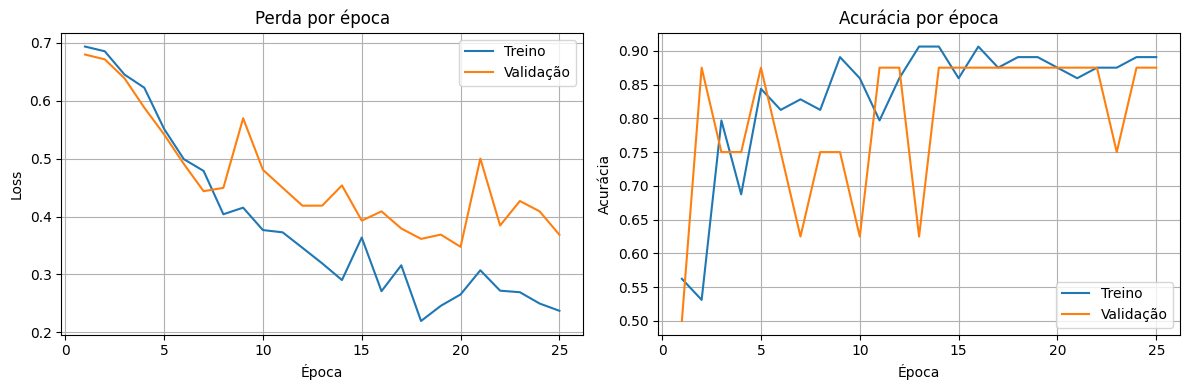

In [ ]:

import matplotlib.pyplot as plt

epocas = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epocas, history.history["loss"], label="Treino")
axes[0].plot(epocas, history.history["val_loss"], label="Validação")
axes[0].set_title("Perda por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epocas, history.history["accuracy"], label="Treino")
axes[1].plot(epocas, history.history["val_accuracy"], label="Validação")
axes[1].set_title("Acurácia por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 11. Resultados e conclusão

A CNN foi desenvolvida do zero para classificar imagens nas categorias controle e copo. A arquitetura possui 25.730 parâmetros treináveis e utiliza imagens RGB redimensionadas para 128 × 128 pixels.

O treinamento da CNN foi realizado durante **25 épocas**, com tempo total de **44,02 segundos**. O uso do *EarlyStopping* permitiu interromper o treinamento conforme o comportamento da perda na validação, restaurando os melhores pesos encontrados.

Esse tempo será utilizado na comparação com os modelos YOLO, considerando que o tempo de treinamento pode variar conforme o hardware e as configurações utilizadas.

Embora os resultados tenham sido positivos, o conjunto de teste possui apenas quatro imagens por classe. Por isso, não é possível concluir que o modelo manterá o mesmo desempenho em imagens novas. Experimentos com um conjunto de teste maior seriam necessários para avaliar melhor sua capacidade de generalização.

Além disso, a CNN realiza classificação da imagem inteira, enquanto o YOLO realiza detecção e localização de objetos. Portanto, a comparação entre as abordagens deve considerar as diferenças entre as tarefas, além das métricas, dos tempos de execução e da facilidade de integração.

## 12. Comparação crítica entre YOLO e CNN

Esta seção reúne os resultados registrados nos notebooks anteriores. Os valores do YOLO foram transcritos dos outputs de avaliação do notebook da Entrega 1; os da CNN vêm dos outputs de avaliação e inferência deste notebook. Se os experimentos forem executados novamente, atualize os valores desta tabela para refletir a nova execução.

**Importante:** o YOLO detecta e localiza objetos com caixas delimitadoras, enquanto a CNN classifica a imagem inteira. Por isso, as métricas mAP do YOLO não são diretamente comparáveis à acurácia da CNN.

In [ ]:
import pandas as pd
from IPython.display import display

comparacao_resultados = pd.DataFrame([
    {
        "Abordagem": "YOLO11n — 30 épocas",
        "Precisão (P)": 0.892,
        "Recall (R)": 1.000,
        "mAP@50": 0.995,
        "mAP@50-95": 0.548,
        "Acurácia CNN": "Não aplicável",
        "Tempo de treinamento": "24 min 32 s",
        "Inferência reportada": "199,3 ms/imagem (YOLO val)"
    },
    {
        "Abordagem": "YOLO11n — 60 épocas",
        "Precisão (P)": 0.970,
        "Recall (R)": 1.000,
        "mAP@50": 0.995,
        "mAP@50-95": 0.782,
        "Acurácia CNN": "Não aplicável",
        "Tempo de treinamento": "48 min 50 s",
        "Inferência reportada": "164,9 ms/imagem (YOLO val)"
    },
    {
        "Abordagem": "CNN do zero",
        "Precisão (P)": 1.000,
        "Recall (R)": 1.000,
        "mAP@50": "Não aplicável",
        "mAP@50-95": "Não aplicável",
        "Acurácia CNN": "100% (8/8 imagens)",
        "Tempo de treinamento": "44,02 s (25 épocas)",
        "Inferência reportada": "18,965 ms/imagem (CPU)"
    }
])

display(comparacao_resultados)

,Abordagem,Precisão (P),Recall (R),mAP@50,mAP@50-95,Acurácia CNN,Tempo de treinamento,Inferência reportada
0,YOLO11n — 30 épocas,0.892,1.0,0.995,0.548,Não aplicável,24 min 32 s,"199,3 ms/imagem (YOLO val)"
1,YOLO11n — 60 épocas,0.970,1.0,0.995,0.782,Não aplicável,48 min 50 s,"164,9 ms/imagem (YOLO val)"
2,CNN do zero,1.000,1.0,Não aplicável,Não aplicável,100% (8/8 imagens),"44,02 s (25 épocas)","18,965 ms/imagem (CPU)"


### Análise dos resultados

**Desempenho do YOLO.** Nos logs de validação mais recentes, ao passar de 30 para 60 épocas, a precisão aumentou de 0,892 para 0,970; o recall permaneceu em 1,000; o mAP@50 permaneceu em 0,995; e o mAP@50-95 aumentou de 0,548 para 0,782. Portanto, o modelo de 60 épocas apresentou melhor mAP@50-95 e maior precisão nessa validação. O conjunto de validação contém apenas oito imagens e oito instâncias, então os resultados devem ser interpretados com cautela.

**Desempenho da CNN.** A CNN obteve 100% de acurácia, precisão, recall e F1-score no conjunto de teste registrado, com quatro imagens por classe. É um resultado positivo para as imagens avaliadas, mas cada imagem representa 12,5 pontos percentuais da acurácia total. Não é suficiente para afirmar que a CNN é superior ao YOLO, pois ela executa outra tarefa e foi avaliada com métricas diferentes.

**Facilidade de uso e integração.** O YOLO oferece uma API pronta e localiza os objetos na imagem, mas exige imagens rotuladas com caixas delimitadoras no formato YOLO e configuração do treinamento. A CNN deste trabalho tem uma arquitetura pequena e direta para classificação da imagem inteira, mas exige definir a arquitetura, o pré-processamento, o treinamento e o pipeline de inferência.

**Tempo de treinamento/customização.** O log do YOLO de 30 épocas registra aproximadamente 24 minutos e 32 segundos; o de 60 épocas, aproximadamente 48 minutos e 50 segundos. A CNN levou 44,02 segundos na execução registrada. Essa comparação depende do hardware, das configurações e do número de épocas; não isola apenas a eficiência da arquitetura.

**Tempo de inferência.** Os logs de validação registraram 199,3 ms/imagem para YOLO de 30 épocas e 164,9 ms/imagem para YOLO de 60 épocas; a CNN registrou 18,965 ms por chamada direta sobre uma imagem já carregada, em CPU. Essas medidas não são perfeitamente equivalentes: o método e o pipeline de medição diferem. Para uma comparação rigorosa, os três modelos precisariam ser cronometrados no mesmo hardware, com o mesmo tratamento de entrada e repetidas execuções.

### Conclusão

Com os resultados disponíveis, o YOLO de 60 épocas apresentou melhor precisão e mAP@50-95 na validação em comparação com o YOLO de 30 épocas, enquanto recall e mAP@50 permaneceram iguais. A CNN teve excelente resultado de classificação e menor tempo registrado de treinamento e de chamada direta de inferência, mas isso não significa que substitua o YOLO quando é necessário localizar o objeto. A principal limitação do estudo é o tamanho reduzido do dataset e dos conjuntos de avaliação. Experimentos com mais imagens e uma medição padronizada de inferência são necessários antes de generalizar as conclusões.